# Example of the aitlas toolbox in the context of multi class image classification

The SynthWakeSAR dataset consists of 3 variants: noise-free images (NF), noisy images (N) with simulated speckle noise, and despeckled SAR images (D). This notebook showcases an example using the noise-free images.

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import SynthWakeSARDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader
import numpy as np

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/SynthWakeSAR/NF/",
    "csv_file": "./data/SynthWakeSAR/NF/synthwakesar_nf_train.csv",
    "selection": "rgb", # set to "all" to use the original 1 band images
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = SynthWakeSARDataset(dataset_config)

## Show images from the dataset

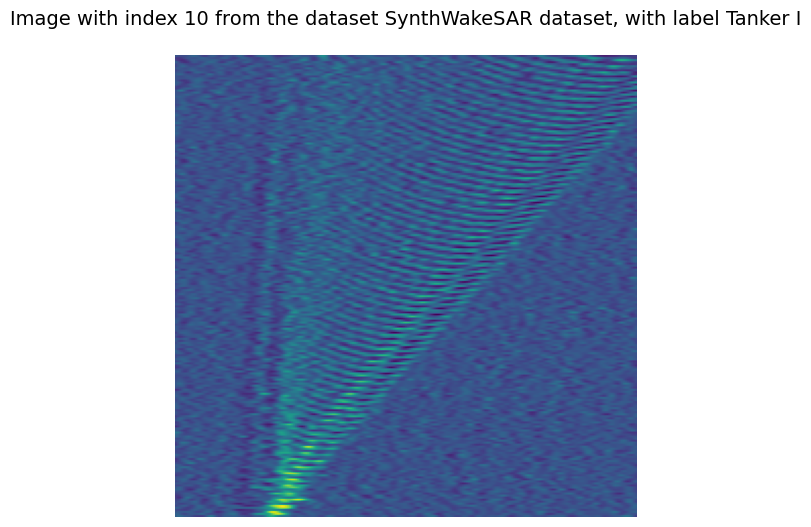

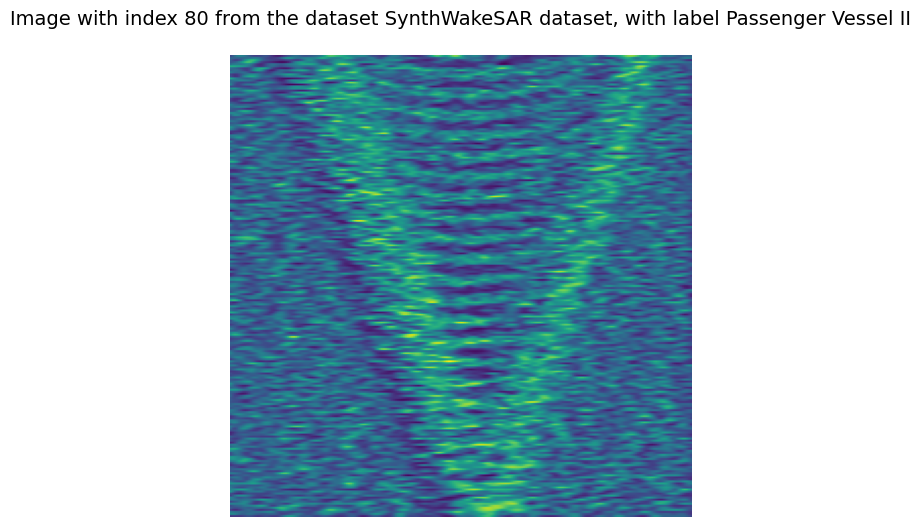

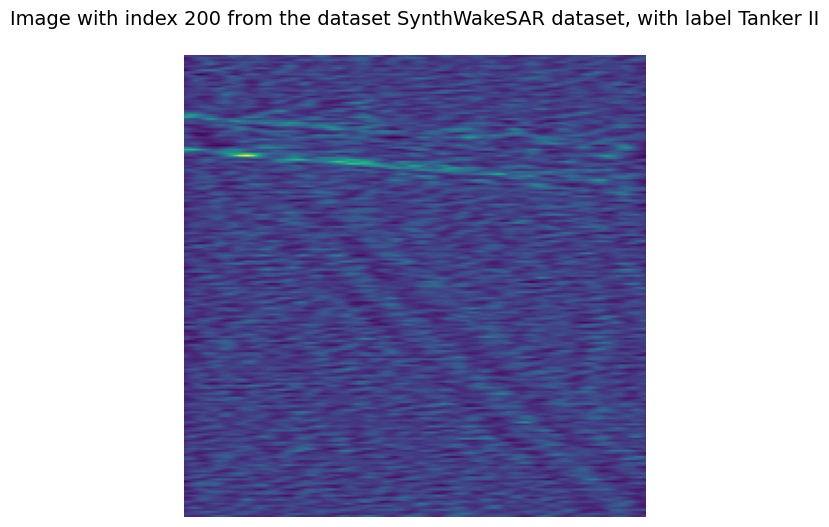

In [15]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

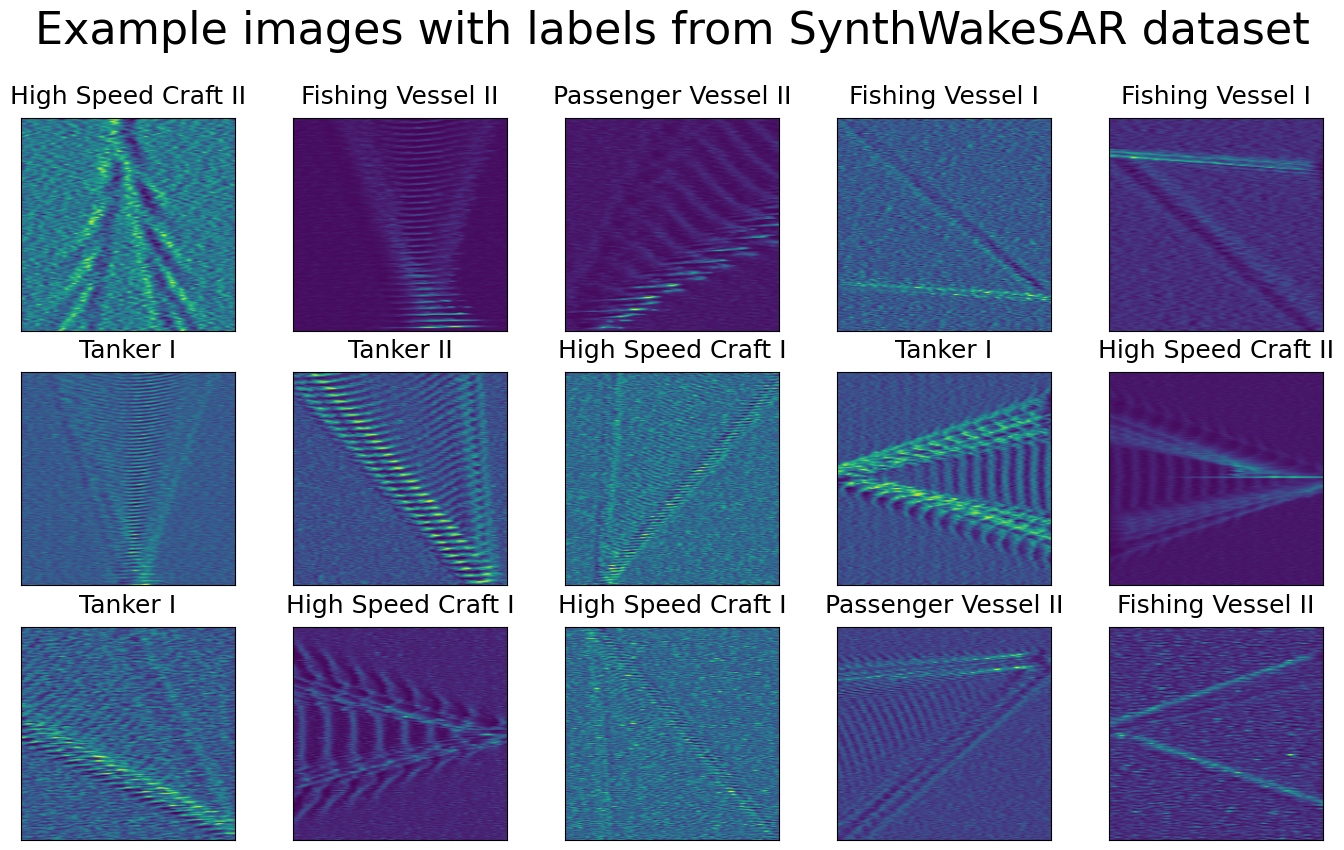

In [7]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [8]:
dataset.show_samples()

,File name,Label
0,High Speed Craft I/7_2974.png,High Speed Craft I
1,Cargo II/2_2857.png,Cargo II
2,Cargo I/1_2570.png,Cargo I
3,Cargo II/2_286.png,Cargo II
4,Fishing Vessel I/9_932.png,Fishing Vessel I
5,Passenger Vessel I/5_1077.png,Passenger Vessel I
6,Cargo II/2_3123.png,Cargo II
7,High Speed Craft I/7_3617.png,High Speed Craft I
8,Cargo I/1_2429.png,Cargo I
9,Passenger Vessel I/5_3941.png,Passenger Vessel I


In [9]:
dataset.data_distribution_table()

,Label,Count
0,Cargo I,2765
1,Cargo II,2765
2,Fishing Vessel I,2765
3,Fishing Vessel II,2764
4,High Speed Craft I,2765
5,High Speed Craft II,2765
6,Passenger Vessel I,2764
7,Passenger Vessel II,2765
8,Tanker I,2765
9,Tanker II,2765


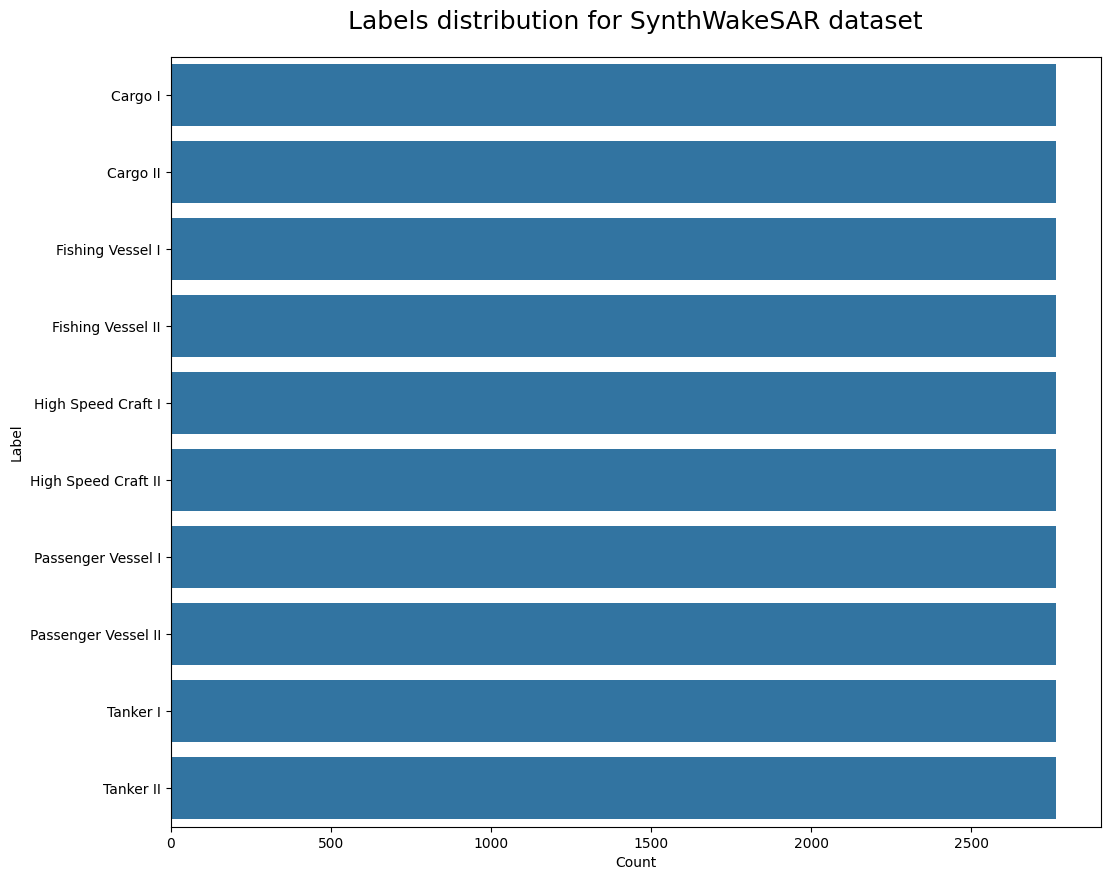

In [10]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/SynthWakeSAR/NF/",
    "csv_file": "./data/SynthWakeSAR/NF/synthwakesar_nf_train.csv",
    "selection": "rgb"
}

train_dataset = SynthWakeSARDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/SynthWakeSAR/NF/",
    "csv_file": "./data/SynthWakeSAR/NF/synthwakesar_nf_val.csv",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = SynthWakeSARDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(27648, 9216)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/SynthWakeSAR/NF/"
model_config = {
    "num_classes": 10, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2026-03-25 11:54:50,953 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2026-03-25 11:54:51,301 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [22]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-28 10:58:09,227 INFO Starting training.
training: 100%|██████████| 1152/1152 [04:48<00:00,  3.99it/s]
2025-05-28 11:02:57,885 INFO epoch: 1, time: 288, loss:  0.63848
testing on train set: 100%|██████████| 1152/1152 [01:41<00:00, 11.34it/s]
2025-05-28 11:04:41,586 INFO Accuracy:0.8909505208333334, Precision Micro:0.8909505208333334, Precision Macro:0.8970387574052424, Precision Weighted:0.8973165756110493, Precision per Class:[0.8676941  0.98366556 0.83094059 0.83761311 0.79571132 0.92227343
 0.99434829 0.96009254 0.88918701 0.88886163], Recall Micro:0.8909505208333334, Recall Macro:0.8912360232161907, Recall Weighted:0.8909505208333334, Recall per Class:[0.80344642 0.96365609 0.91646192 0.9327342  0.94444444 0.81200974
 0.75876011 0.89103596 0.9042292  0.98558215], F1_score Micro:0.8909505208333327, F1_score Macro:0.8905850372606677, F1_score Weighted:0.890576397094252, F1_score per Class:[0.83433524 0.97355802 0.87160846 0.88261822 0.86372169 0.86363636
 0.86072466 0.92427617

0.10690756266750315

## Test the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/SynthWakeSAR/NF/",
    "csv_file": "./data/SynthWakeSAR/NF/synthwakesar_nf_test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = SynthWakeSARDataset(test_dataset_config)
model_path = "./data/experiments/SynthWakeSAR/NF/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-28 12:06:26,918 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SynthWakeSAR/NF/checkpoint.pth.tar
2025-05-28 12:06:27,201 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SynthWakeSAR/NF/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 288/288 [00:14<00:00, 19.36it/s]


[{'Accuracy': 0.9663628472222222},
 {'Precision Micro': 0.9663628472222222,
  'Precision Macro': 0.9667010645625052,
  'Precision Weighted': 0.9666893182831754,
  'Precision per Class': array([0.94444444, 0.98308668, 0.92635659, 0.95512821, 0.98268398,
         0.94618834, 0.95842956, 1.        , 0.99170124, 0.9789916 ])},
 {'Recall Micro': 0.9663628472222222,
  'Recall Macro': 0.9665615463307414,
  'Recall Weighted': 0.9663628472222223,
  'Recall per Class': array([0.93363844, 0.99358974, 0.9755102 , 0.92931393, 0.93223819,
         0.95475113, 0.98341232, 0.98591549, 0.98151951, 0.9957265 ])},
 {'F1_score Micro': 0.9663628472222217,
  'F1_score Macro': 0.9664450489499877,
  'F1_score Weighted': 0.9663329140291144,
  'F1_score per Class': array([0.93901036, 0.98831031, 0.95029821, 0.94204426, 0.95679663,
         0.95045045, 0.97076023, 0.9929078 , 0.98658411, 0.98728814])}]

## Predictions

2025-05-28 12:06:45,634 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SynthWakeSAR/NF/checkpoint.pth.tar
2025-05-28 12:06:45,893 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SynthWakeSAR/NF/checkpoint.pth.tar at epoch 11


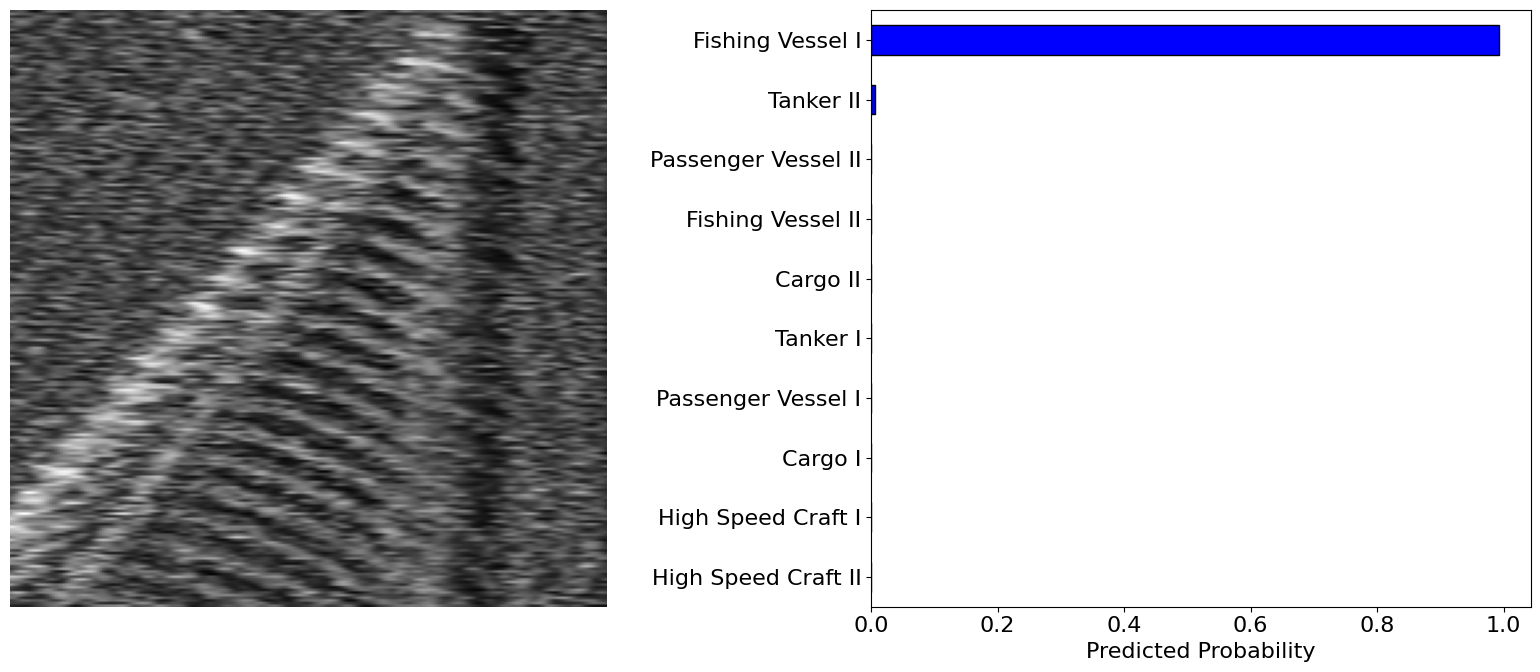

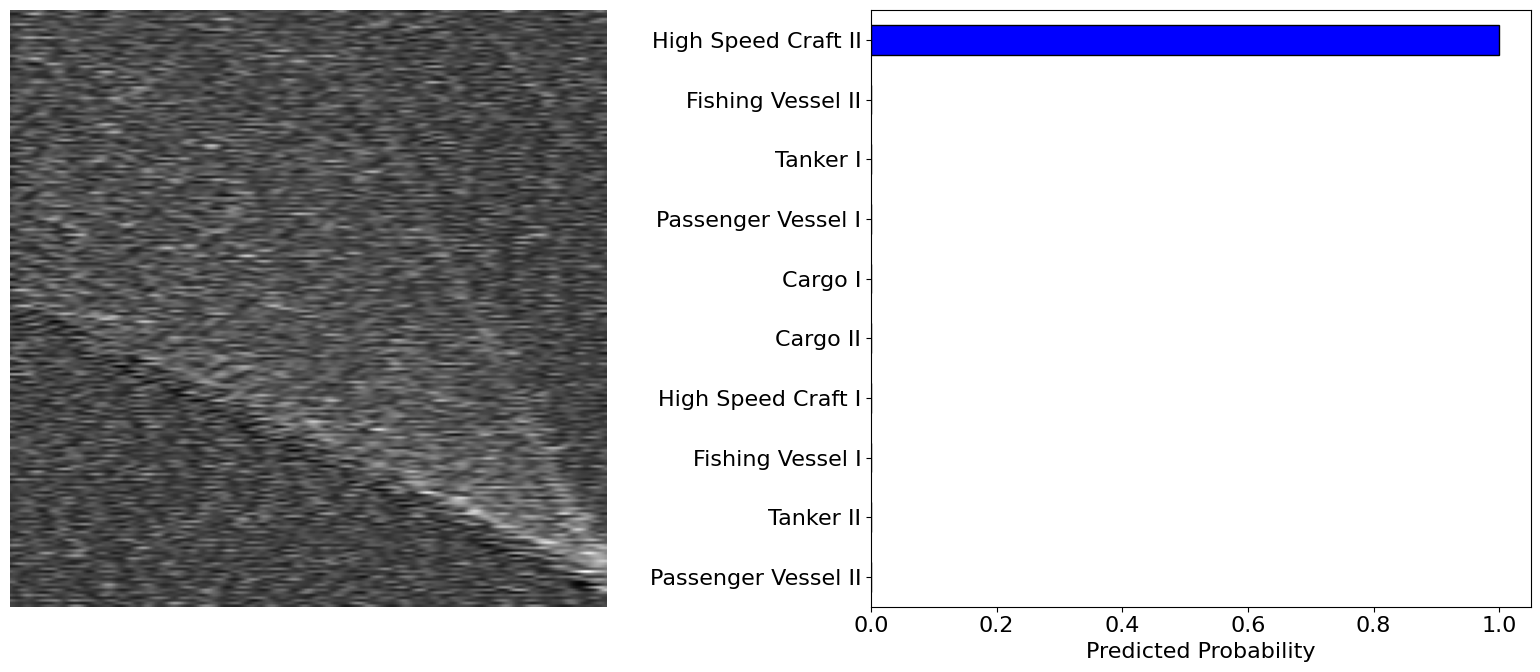

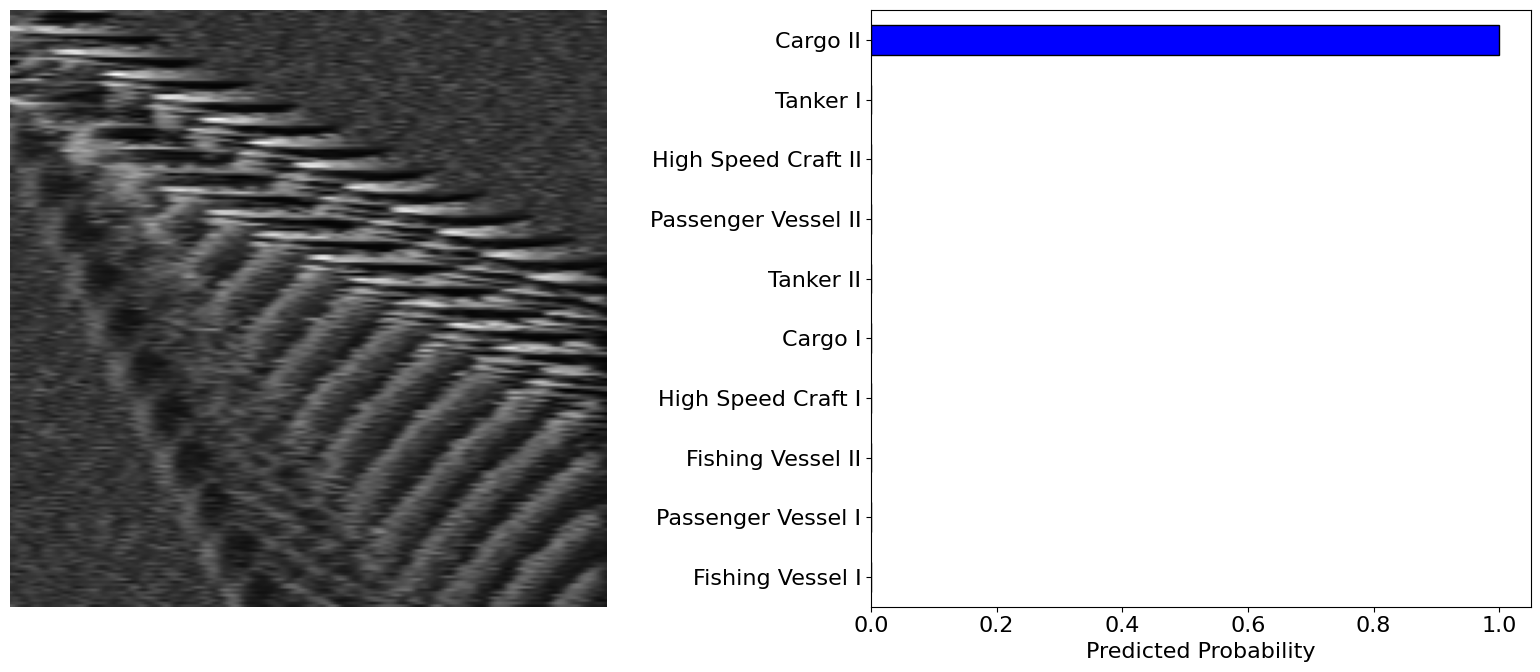

In [ ]:
labels = ["Cargo I","Cargo II","Tanker I","Tanker II","Passenger Vessel I","Passenger Vessel II",
          "High Speed Craft I","High Speed Craft II","Fishing Vessel I","Fishing Vessel II"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/SynthWakeSAR/NF/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/SynthWakeSAR/NF/Fishing Vessel I/9_888.png')
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/SynthWakeSAR/NF/High Speed Craft II/8_661.png')
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/SynthWakeSAR/NF/Cargo II/2_137.png')
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)